# D01 — infrastructure: railroads, canals, steamboat rivers, named roads (layer 6)
Task `tasks/T-009-d01-infrastructure.md` (brief B-020). Format and reprojection only; no ML/LLM. Reads `data/raw/` and `data/processed/places|residences` read-only; writes one file: `web/data/infrastructure.topojson`.

**Sources**
- Railroads: Atack (2016), `data/raw/gis/atack-transport/RR1826-1911Modified103123/`. Grain: track segment; `InOpBy` = publication year of the later of two maps (so "in operation by", approximate), `ExactDate` = opening year from the Hallberg database, adjusted by Atack (Atack 2021, 39–40).
- Canals: Atack (2017), `19thC_Canals_March2017/`. Grain: canal section; `OPENED`, `CLOSED` (2100 = still open).
- Steamboat rivers: Atack (2015), `SteamboatNavigatedRiverContigUSAprojection/`. Grain: river stretch; `START` = first steamboat use found by Atack, `END` (2100 = navigation continues; Atack 2021, 24). `Tidal` = 1 for tidal reaches.
- Named roads: `research/roads_R7.csv` (historian pass, B-014), `research/R7-layers-history.md`. Grain: one road / route; no geometry yet.

All three Atack files are USA Contiguous Albers (ESRI:102003); output is EPSG:4326, clipped to the shared map extent (`extent` in `relief_bounds.json`, from E01; T-011). **No licence is stated** for the Atack files (R6): ask Jeremy Atack before publishing derived lines.

**References**
- Atack, Jeremy. 2015. "Historical Geographic Information Systems (GIS) Database of Steamboat-Navigated Rivers during the Nineteenth Century in the United States." Vanderbilt University. https://my.vanderbilt.edu/jeremyatack/data-downloads/.
- Atack, Jeremy. 2016. "Historical Geographic Information Systems (GIS) Database of U.S. Railroads." Rev. October 2023. Vanderbilt University. https://my.vanderbilt.edu/jeremyatack/data-downloads/.
- Atack, Jeremy. 2017. "Historical Geographic Information Systems (GIS) Database of Nineteenth Century U.S. Canals." Vanderbilt University. https://my.vanderbilt.edu/jeremyatack/data-downloads/.
- Atack, Jeremy. 2021. "Creating Historical Transportation Shapefiles." Rev. February. Vanderbilt University.

In [1]:
import sys, json
from pathlib import Path
PIPELINE_DIR = Path.cwd().parent
if str(PIPELINE_DIR) not in sys.path: sys.path.insert(0, str(PIPELINE_DIR))
import config
import duckdb, numpy as np, pandas as pd, geopandas as gpd
import shapely
from shapely.ops import linemerge
import matplotlib.pyplot as plt
pd.set_option('display.width', 220); pd.set_option('display.max_rows', 120); pd.set_option('display.max_colwidth', 80)

ATACK = config.RAW_DIR / 'gis' / 'atack-transport'
R7_CSV = config.PROJECT_DIR / 'research' / 'roads_R7.csv'
OUT = config.PROJECT_DIR / 'web' / 'data' / 'infrastructure.topojson'
CUTOFF = 1840
SIMPLIFY_M = 100   # Douglas-Peucker tolerance in Albers metres, before reprojecting

con = duckdb.connect()
# T-011: shared map extent = relief bounds, written by E01 (was: places in residences + 1 degree, T-006)
EXTENT = json.loads((config.PROJECT_DIR / 'web' / 'data' / 'relief_bounds.json').read_text())['extent']
EXT_BOX = shapely.box(*EXTENT)
print('extent (lon/lat):', [round(v, 4) for v in EXTENT])

extent (lon/lat): [-100.0, 24.9083, -66.6167, 47.4417]


## 1. Railroads (Atack 2016)
Keep segments with `InOpBy` ≤ 1840. `year_open` = `InOpBy` (`date_quality` = approximate); `ExactDate` kept as `year_exact` for tooltips (0 → null).
Segments are dissolved to one feature per railroad name × `InOpBy` × `ExactDate`, so each feature keeps one date; `STATENAM` (1900 state borders) becomes a list.

In [2]:
rr_all = gpd.read_file(ATACK / 'RR1826-1911Modified103123' / 'RR1826-1911Modified103123.shp')
rr = rr_all[rr_all.InOpBy <= CUTOFF].copy()
print(f'{len(rr_all):,} segments in file; {len(rr):,} with InOpBy <= {CUTOFF}; {rr.Miles.sum():,.0f} mi')
print('InOpBy:', rr.InOpBy.value_counts().sort_index().to_dict())
print('ExactDate:', rr.ExactDate.value_counts().sort_index().to_dict())
print('ExactDate later than InOpBy:'); print(rr.loc[rr.ExactDate > rr.InOpBy, ['RRname', 'InOpBy', 'ExactDate', 'Miles']])

76,849 segments in file; 1,579 with InOpBy <= 1840; 3,161 mi
InOpBy: {1830: 55, 1835: 583, 1837: 2, 1839: 2, 1840: 937}
ExactDate: {0: 1, 1827: 10, 1829: 11, 1830: 34, 1831: 41, 1832: 35, 1833: 51, 1834: 168, 1835: 288, 1836: 118, 1837: 129, 1838: 143, 1839: 148, 1840: 399, 1842: 2, 1850: 1}
ExactDate later than InOpBy:
                    RRname  InOpBy  ExactDate     Miles
2074  Portsmouth & Roanoke    1840       1850  7.104513
5034    Baltimore and Ohio    1839       1842  0.216831
5035    Baltimore and Ohio    1839       1842  0.022449


In [3]:
rr['ExactDate'] = rr.ExactDate.where(rr.ExactDate > 0)
rr_d = (rr.dissolve(by=['RRname', 'InOpBy', 'ExactDate'], dropna=False,
                    aggfunc={'Miles': 'sum', 'STATENAM': lambda s: '; '.join(sorted(set(s.dropna())))})
          .reset_index())
rr_d['geometry'] = rr_d.geometry.apply(lambda g: linemerge(g) if g.geom_type == 'MultiLineString' else g)
rail = gpd.GeoDataFrame({
    'kind': 'rail', 'name': rr_d.RRname, 'year_open': rr_d.InOpBy.astype(int),
    'date_quality': 'approximate (InOpBy: map year)',
    'year_exact': rr_d.ExactDate.astype('Int64'), 'states_1900': rr_d.STATENAM,
    'miles': rr_d.Miles.round(1), 'source': 'Atack 2016',
}, geometry=rr_d.geometry, crs=rr.crs)
print(f'{len(rail)} rail features from {len(rr)} segments; {rail.name.nunique()} names')
rail.drop(columns='geometry').head()

120 rail features from 1579 segments; 111 names


,kind,name,year_open,date_quality,year_exact,states_1900,miles,source
0,rail,Allegheny Portage,1835,approximate (InOpBy: map year),1834,Pennsylvania,22.2,Atack 2016
1,rail,Allegheny inclined plane (abandoned 1854),1835,approximate (InOpBy: map year),1834,Pennsylvania,13.5,Atack 2016
2,rail,Annapolis & Elk Ridge,1840,approximate (InOpBy: map year),1840,Maryland,25.0,Atack 2016
3,rail,Auburn & Syracuse,1840,approximate (InOpBy: map year),1838,New York,26.8,Atack 2016
4,rail,Baltimore & Ohio,1830,approximate (InOpBy: map year),1830,Maryland,15.8,Atack 2016


## 2. Canals (Atack 2017)
Keep sections with `OPENED` ≤ 1840. `year_open` = `OPENED` (`date_quality` = stated); `CLOSED` → `year_close` (2100 → null, still open).

In [4]:
cn_all = gpd.read_file(ATACK / '19thC_Canals_March2017' / '19thC_Canals_March2017.shp')
cn = cn_all[cn_all.OPENED <= CUTOFF].copy()
print(f'{len(cn_all)} sections in file; {len(cn)} opened <= {CUTOFF}; {cn.NAME.nunique()} names')
print('closed by 1840:'); print(cn.loc[cn.CLOSED <= CUTOFF, ['NAME', 'OPENED', 'CLOSED']])
canal = gpd.GeoDataFrame({
    'kind': 'canal', 'name': cn.NAME, 'year_open': cn.OPENED.astype(int),
    'date_quality': 'stated (OPENED)',
    'year_close': cn.CLOSED.where(cn.CLOSED < 2100).astype('Int64'),
    'miles': cn.LENGHT.round(1), 'reference': cn.REFERENCE, 'source': 'Atack 2017',
}, geometry=cn.geometry, crs=cn.crs).reset_index(drop=True)
canal.drop(columns='geometry').head()

155 sections in file; 113 opened <= 1840; 71 names
closed by 1840:
                                      NAME  OPENED  CLOSED
80  Granville Feeder (Ohio and line Canal)    1832    1838


,kind,name,year_open,date_quality,year_close,miles,reference,source
0,canal,Cumberland and Oxford,1830,stated (OPENED),1873,34.8,http://www.napleshs.org/cumberland___oxford_canal.html See also http://en.wi...,Atack 2017
1,canal,Middlesex Canal,1803,stated (OPENED),1853,27.8,http://www.winchestermass.org/canal.html,Atack 2017
2,canal,Middlesex Canal/Merrimack (Concord Extension),1815,stated (OPENED),1853,49.4,http://www.geocities.com/athens/troy/6034/,Atack 2017
3,canal,Blackstone Canal,1828,stated (OPENED),1848,47.0,http://en.wikipedia.org/wiki/Blackstone_Canal also http://www.mass.gov/dcr/p...,Atack 2017
4,canal,New Haven and Northampton (to Farmington),1828,stated (OPENED),1847,29.7,http://en.wikipedia.org/wiki/Hampshire_and_Hampden_Canal,Atack 2017


## 3. Steamboat rivers (Atack 2015)
Keep stretches with `START` ≤ 1840. `year_open` = `START` (`date_quality` = approximate). The 24 tidal reaches all carry `START` = 1787 and no source:
a floor for the series, not a first-steamboat date (R6), so they are marked `placeholder (tidal, 1787)`. `END` → `year_close` (2100 → null).

In [5]:
sb_all = gpd.read_file(ATACK / 'SteamboatNavigatedRiverContigUSAprojection' / 'SteamboatNavigatedRiverContigUSAprojection.shp')
sb = sb_all[sb_all.START <= CUTOFF].copy()
print(f'{len(sb_all)} stretches in file; {len(sb)} with START <= {CUTOFF}; tidal: {int(sb.Tidal.sum())}')
print(pd.crosstab(sb.START == 1787, sb.Tidal, rownames=['START==1787'], colnames=['Tidal']))
steam = gpd.GeoDataFrame({
    'kind': 'steamboat', 'name': sb.NAME, 'year_open': sb.START.astype(int),
    'date_quality': np.where((sb.START == 1787) & (sb.Tidal == 1), 'placeholder (tidal, 1787)', 'approximate (START)'),
    'year_close': sb.END.where(sb.END < 2100).astype('Int64'),
    'head_of_navigation': sb.HEADNAV, 'tidal': sb.Tidal.astype(int),
    'reference': sb.SOURCE, 'source': 'Atack 2015',
}, geometry=sb.geometry, crs=sb.crs).reset_index(drop=True)
steam.drop(columns='geometry').head()

226 stretches in file; 146 with START <= 1840; tidal: 27
Tidal          0   1
START==1787         
False        119   3
True           0  24


,kind,name,year_open,date_quality,year_close,head_of_navigation,tidal,reference,source
0,steamboat,Allegheny River,1830,approximate (START),<NA>,Warren (occasionally as high as Olean),0,http://www.paintedhills.org/CATTARAUGUS/steamboat.htm,Atack 2015
1,steamboat,Altamaha River,1819,approximate (START),<NA>,Confluence of Oconee and Ocmulgee rivers,0,http://dlg.galileo.usg.edu/georgiabooks/pdfs/gb0088.pdf,Atack 2015
2,steamboat,Amite River,1819,approximate (START),<NA>,few miles above junction w/ Bayou Manchac,0,"Annual report of the Secretary of War, Volume 2, 1891 By United States. Wa...",Atack 2015
3,steamboat,Apalachicola River,1828,approximate (START),<NA>,Confluence of Chattahoochee & Flint rivers,0,http://jacksoncountytdc.com/the-rivers-become-arteries-of-pioneer-life.html,Atack 2015
4,steamboat,Atchafalaya River,1819,approximate (START),<NA>,Confluence with Red River,0,"Foreign commerce and navigation of the United State, 1888",Atack 2015


## 4. Named roads and routes (R7)
23 rows, attribute records only: geometry is empty and `todo` = `hand-trace` (a later task).
`year_open` = the **wagon-passable** year where R7 states one (Wilderness Road 1796, NPS/FHWA; 1795 per Speed. Zane's Trace 1804, "wagon road only after Ohio's 1804 appropriation"; Crown Point Road 1760, "widened for wagons");
otherwise R7's own `year_open` (`year_basis` = `r7_year_open`, wagon status not stated). R7's `year_open`, `year_authorized` and `year_note` stay for tooltips.
R7 `kind` is mapped to the PLAN kinds (road / canal / route) and kept as `kind_as_r7`. The three R7 canals are also in Atack; `atack_match` names the Atack sections.

In [6]:
r7 = pd.read_csv(R7_CSV)
WAGON_YEAR = {  # id: (year, note) — only where R7 states a wagon year
    'R7-05': (1796, 'wagon road 1796 (NPS, FHWA); 1795 per Speed via Armao'),
    'R7-13': (1804, 'wagon road only after the 1804 Ohio appropriation (R7)'),
    'R7-04': (1760, 'widened for wagons 1760 (R7)'),
}
KIND = {'road': 'road', 'military road': 'road', 'turnpike': 'road', 'trace / post road': 'road',
        'post road; military road': 'road', 'river route': 'route', 'canal': 'canal', 'canal and railroad': 'canal'}
ATACK_NAME = {'R7-21': r'^Erie Canal', 'R7-22': r'Ohio and Erie', 'R7-23': r'^Main ?[Ll]ine'}
def atack_match(rid):
    if rid not in ATACK_NAME: return None
    m = cn_all[cn_all.NAME.str.contains(ATACK_NAME[rid], na=False)]
    return f"{'; '.join(sorted(m.NAME.unique()))} ({len(m)} sections, opened {m.OPENED.min()}-{m.OPENED.max()})"

assert r7.kind.isin(KIND.keys()).all(), set(r7.kind) - set(KIND)
roads = pd.DataFrame({
    'r7_id': r7.id, 'kind': r7.kind.map(KIND), 'kind_as_r7': r7.kind, 'name': r7.name,
    'year_open': [WAGON_YEAR.get(i, (y, None))[0] for i, y in zip(r7.id, r7.year_open)],
    'year_basis': ['wagon' if i in WAGON_YEAR else ('r7_year_open' if pd.notna(y) else None) for i, y in zip(r7.id, r7.year_open)],
    'wagon_note': [WAGON_YEAR.get(i, (None, None))[1] for i in r7.id],
    'year_open_r7': r7.year_open.astype('Int64'), 'year_authorized': r7.year_authorized.astype('Int64'),
    'year_note': r7.year_note, 'date_quality': r7.status,
    'other_names': r7.other_names, 'endpoint_a': r7.endpoint_a, 'endpoint_b': r7.endpoint_b, 'via': r7.via,
    'native_path_basis': r7.native_path_basis, 'nations_on_route_as_named': r7.nations_on_route_as_named,
    'unverified_note': r7.unverified_note, 'reference': r7.source, 'source_url': r7.source_url,
    'atack_match': [atack_match(i) for i in r7.id],
    'source': 'R7 (roads_R7.csv)', 'todo': 'hand-trace',
})
roads['year_open'] = roads.year_open.astype('Int64')
roads = gpd.GeoDataFrame(roads, geometry=gpd.GeoSeries([None] * len(roads)), crs='EPSG:4326')
roads[['r7_id', 'kind', 'name', 'year_open', 'year_basis', 'year_open_r7', 'year_authorized', 'date_quality', 'atack_match']]

,r7_id,kind,name,year_open,year_basis,year_open_r7,year_authorized,date_quality,atack_match
0,R7-01,road,Great Wagon Road,<NA>,NaN,<NA>,<NA>,partial,NaN
1,R7-02,road,Forbes Road,1758,r7_year_open,1758,<NA>,partial,NaN
2,R7-03,road,Braddock's Road,1755,r7_year_open,1755,<NA>,unverified,NaN
3,R7-04,road,Crown Point Road,1760,wagon,1760,<NA>,partial,NaN
4,R7-05,road,Wilderness Road,1796,wagon,1775,1779,partial,NaN
5,R7-06,road,Avery's Trace,1788,r7_year_open,1788,1787,verified,NaN
6,R7-07,road,Walton Road,1802,r7_year_open,1802,1795,verified,NaN
7,R7-08,road,Philadelphia and Lancaster Turnpike,1795,r7_year_open,1795,<NA>,partial,NaN
8,R7-09,road,Great Genesee Road,1797,r7_year_open,1797,1794,partial,NaN
9,R7-10,road,Mohawk Turnpike,<NA>,NaN,<NA>,1800,partial,NaN


## 5. Combine → EPSG:4326
Atack lines are simplified at 100 m in Albers (well under a pixel at state scale), then reprojected. One table, one `id` per feature.

In [7]:
lines = pd.concat([rail, canal, steam], ignore_index=True)
lines['geometry'] = lines.geometry.simplify(SIMPLIFY_M, preserve_topology=True)
lines = gpd.GeoDataFrame(lines, geometry='geometry', crs=rail.crs).to_crs('EPSG:4326')
infra = gpd.GeoDataFrame(pd.concat([lines, roads], ignore_index=True), geometry='geometry', crs='EPSG:4326')
infra.insert(0, 'id', infra.groupby('kind').cumcount().add(1).astype(str).radd(infra.kind + '-').str.replace(r'-(\d+)$', lambda m: '-' + m.group(1).zfill(4), regex=True))
infra.loc[infra.r7_id.notna(), 'id'] = infra.r7_id
infra = infra.drop(columns='r7_id')
print(infra.kind.value_counts().to_dict(), '| with geometry:', int(infra.geometry.notna().sum()))

{'steamboat': 146, 'rail': 120, 'canal': 116, 'road': 19, 'route': 1} | with geometry: 379


### 5b. Clip to the shared map extent (T-011)
Lines crossing the extent are cut to it (`clipped_to_extent = true`); lines wholly outside drop out. R7 roads have no geometry and stay. `miles` stays the Atack value for the whole feature.

In [8]:
def clip_to_extent(g):
    """Line parts of g inside EXT_BOX -> (geometry or None, status)."""
    if g is None or g.is_empty: return None, 'no_geometry'
    if EXT_BOX.covers(g): return g, 'inside'
    parts = [p for p in shapely.get_parts(shapely.get_parts(g.intersection(EXT_BOX))) if p.geom_type == 'LineString' and not p.is_empty]
    if not parts: return None, 'outside'
    return (parts[0] if len(parts) == 1 else shapely.MultiLineString(parts)), 'clipped'
n_infra0 = len(infra)
cut = [clip_to_extent(g) for g in infra.geometry]
infra['_clip'] = [s for _, s in cut]
infra = infra.set_geometry(gpd.GeoSeries([g for g, _ in cut], crs='EPSG:4326'))
infra['clipped_to_extent'] = infra._clip == 'clipped'
display(pd.crosstab(infra.kind, infra._clip, margins=True))
print(infra.loc[infra._clip != 'inside', ['id', 'kind', 'name', 'year_open', '_clip']].query("_clip != 'no_geometry'").to_string())
infra_out = infra[infra._clip == 'outside']
infra = infra[infra._clip != 'outside'].drop(columns='_clip').reset_index(drop=True)
print(f'infrastructure: {n_infra0} features before -> {len(infra)} after ({len(infra_out)} dropped)')

_clip,clipped,inside,no_geometry,outside,All
kind,,,,,
canal,0,113,3,0,116
rail,0,120,0,0,120
road,0,0,19,0,19
route,0,0,1,0,1
steamboat,1,138,0,7,146
All,1,371,23,7,402


                 id       kind                                name  year_open    _clip
320  steamboat-0088  steamboat                    Willamette River       1836  outside
331  steamboat-0099  steamboat                      Missouri River       1831  clipped
332  steamboat-0100  steamboat                      Missouri River       1832  outside
342  steamboat-0110  steamboat  Columbia River Lower (Dalles down)       1836  outside
350  steamboat-0118  steamboat                    Willamette River       1836  outside
371  steamboat-0139  steamboat                Columbia River Lower       1836  outside
375  steamboat-0143  steamboat                      Chehalis River       1836  outside
376  steamboat-0144  steamboat                      Coquille River       1836  outside
infrastructure: 402 features before -> 395 after (7 dropped)


## 6. Feature counts by kind and decade of `year_open`

In [9]:
counts = infra.drop(columns='geometry').assign(year_open=lambda d: d.year_open.astype('float'))
con.register('infra_attr', counts)
by_dec = con.sql('''select kind, coalesce(cast(cast(year_open as int)//10*10 as varchar)||'s', 'undated') as "decade", count(*) n
  from infra_attr group by all order by kind, "decade"''').df()
print(by_dec.pivot(index='decade', columns='kind', values='n').fillna(0).astype(int).assign(total=lambda d: d.sum(axis=1)))

kind     canal  rail  road  route  steamboat  total
decade                                             
1750s        0     0     2      0          0      2
1760s        0     0     1      0          0      1
1780s        0     0     1      0         24     25
1790s        1     0     3      0          1      5
1800s        4     0     3      0          4     11
1810s        3     0     2      0         28     33
1820s       39     0     1      0         32     72
1830s       62    47     0      0         43    152
1840s        7    73     0      0          7     87
undated      0     0     6      1          0      7


## 7. Write TopoJSON
Small encoder (no new dependency): one object `infrastructure`, one arc per line part, quantized to 1e5 and delta-encoded. Features with no geometry are written as `"type": null` with their properties.
Null properties are left out of each feature to keep the file small.

In [10]:
def to_topojson(gdf, name, q=100_000):
    x0, y0, x1, y1 = gdf.geometry.dropna().total_bounds
    kx, ky = (x1 - x0) / (q - 1), (y1 - y0) / (q - 1)
    arcs, geoms = [], []
    def arc(coords):
        p = np.round((np.asarray(coords)[:, :2] - [x0, y0]) / [kx, ky]).astype(np.int64)
        keep = np.r_[True, (np.diff(p, axis=0) != 0).any(axis=1)]
        p = p[keep]
        if len(p) < 2: p = np.vstack([p, p])
        d = np.vstack([p[:1], np.diff(p, axis=0)])
        arcs.append(d.tolist()); return len(arcs) - 1
    def clean(v):
        if v is None or v is pd.NA or (isinstance(v, float) and np.isnan(v)): return None
        return v.item() if hasattr(v, 'item') else v
    for rec in gdf.drop(columns='geometry').to_dict('records'):
        geoms.append({'properties': {k: clean(v) for k, v in rec.items() if clean(v) is not None}})
    for g, out in zip(gdf.geometry, geoms):
        if g is None or g.is_empty: out['type'] = None
        elif g.geom_type == 'LineString': out.update(type='LineString', arcs=[arc(g.coords)])
        elif g.geom_type == 'MultiLineString': out.update(type='MultiLineString', arcs=[[arc(p.coords)] for p in g.geoms])
        else: raise ValueError(g.geom_type)
    return {'type': 'Topology', 'transform': {'scale': [kx, ky], 'translate': [x0, y0]},
            'bbox': [x0, y0, x1, y1], 'objects': {name: {'type': 'GeometryCollection', 'geometries': geoms}}, 'arcs': arcs}

topo = to_topojson(infra, 'infrastructure')
OUT.parent.mkdir(parents=True, exist_ok=True)
OUT.write_text(json.dumps(topo, separators=(',', ':'), ensure_ascii=False))
size_mb = OUT.stat().st_size / 1e6
print(f'{OUT.relative_to(config.PROJECT_DIR)}: {size_mb:.2f} MB, {len(topo["arcs"]):,} arcs, {len(topo["objects"]["infrastructure"]["geometries"])} features')

web/data/infrastructure.topojson: 0.46 MB, 538 arcs, 395 features


In [11]:
# Reference check: decode with topojson-client (the web app's decoder, web/node_modules) via node.
# Per object: features, null geometries, rings (bad = < 4 positions or not closed), lines (bad = < 2 positions).
TOPO_CHECK_JS = r'''
const tc = require(process.argv[1]), fs = require('fs'), out = {};
const pt = p => Array.isArray(p) && p.length === 2 && Number.isFinite(p[0]) && Number.isFinite(p[1]);
for (const f of process.argv.slice(2)) {
  const t = JSON.parse(fs.readFileSync(f, 'utf8')); out[f] = {};
  for (const [k, o] of Object.entries(t.objects)) {
    const r = {features: 0, null: 0, points: 0, rings: 0, bad_rings: 0, lines: 0, bad_lines: 0, bad_type: 0, x0: Infinity, y0: Infinity, x1: -Infinity, y1: -Infinity};
    const bb = p => { r.x0 = Math.min(r.x0, p[0]); r.y0 = Math.min(r.y0, p[1]); r.x1 = Math.max(r.x1, p[0]); r.y1 = Math.max(r.y1, p[1]); };   // T-011: bbox of every position
    const ring = c => { r.rings++; c.forEach(bb); const ok = c.length >= 4 && c.every(pt) && c[0][0] === c[c.length-1][0] && c[0][1] === c[c.length-1][1]; if (!ok) r.bad_rings++; };
    const line = c => { r.lines++; c.forEach(bb); if (!(c.length >= 2 && c.every(pt))) r.bad_lines++; };
    for (const ft of tc.feature(t, o).features) {
      r.features++; const g = ft.geometry;
      if (!g) { r.null++; continue; }
      if (g.type === 'Polygon') g.coordinates.forEach(ring);
      else if (g.type === 'MultiPolygon') g.coordinates.forEach(p => p.forEach(ring));
      else if (g.type === 'LineString') line(g.coordinates);
      else if (g.type === 'MultiLineString') g.coordinates.forEach(line);
      else if (g.type === 'Point') { r.points += pt(g.coordinates) ? 1 : 0; bb(g.coordinates); }
      else r.bad_type++;
    }
    out[f][k] = r;
  }
}
console.log(JSON.stringify(out));
'''
def topojson_client_check(paths):
    """-> DataFrame (file, object) of counts from topojson-client; raises if node fails."""
    import subprocess
    lib = config.PROJECT_DIR / 'web' / 'node_modules' / 'topojson-client'
    r = subprocess.run(['node', '-e', TOPO_CHECK_JS, str(lib)] + [str(p) for p in paths], capture_output=True, text=True, check=True)
    return pd.DataFrame([dict(file=Path(f).name, object=k, **v) for f, objs in json.loads(r.stdout).items() for k, v in objs.items()])

def assert_inside(chk, extent, tol=1e-9):
    """T-011: every decoded position of every object lies inside extent [west, south, east, north] (objects with no geometry: NaN bbox, skipped)."""
    w, s, e, n = extent; c = chk.dropna(subset=['x0'])
    bad = c[(c.x0 < w - tol) | (c.y0 < s - tol) | (c.x1 > e + tol) | (c.y1 > n + tol)]
    assert bad.empty, bad[['file', 'object', 'x0', 'y0', 'x1', 'y1']]
    return c[['file', 'object', 'x0', 'y0', 'x1', 'y1']]

## 8. Read back and plot inside the extent
Decode the file (not the in-memory table) and draw it with the shared extent box. Lines are clipped to it (§5b), so every line lies inside.

decoded 395 features, 372 with lines; bounds [-100.0, 26.52, -67.06, 45.4]
lines fully inside the extent: 372 / 372
Empty DataFrame
Columns: [id, kind, name, year_open, bounds]
Index: []
west of -100: Empty DataFrame
Columns: [id, kind, name, year_open, date_quality]
Index: []


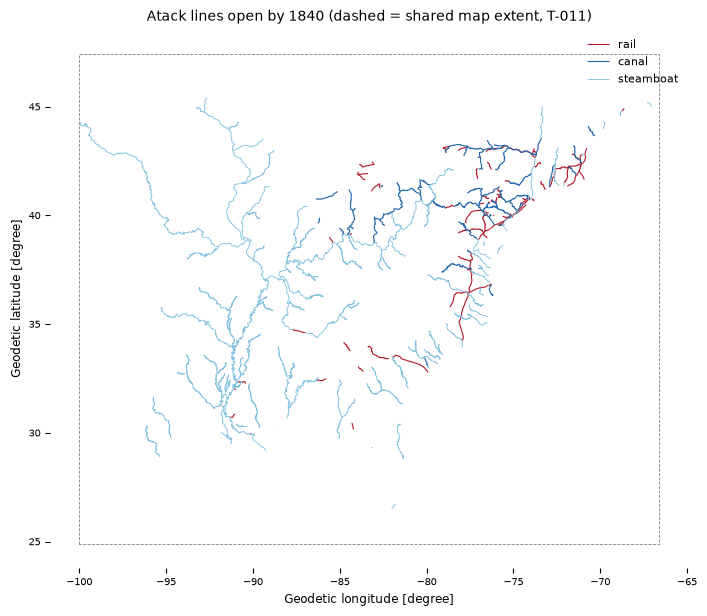

In [12]:
t = json.loads(OUT.read_text())
(sx, sy), (tx, ty) = t['transform']['scale'], t['transform']['translate']
dec = [np.cumsum(np.array(a), axis=0) * [sx, sy] + [tx, ty] for a in t['arcs']]
def geom(g):
    if g['type'] == 'LineString': return shapely.LineString(dec[g['arcs'][0]])
    if g['type'] == 'MultiLineString': return shapely.MultiLineString([dec[p[0]] for p in g['arcs']])
    return None
gs = t['objects']['infrastructure']['geometries']
back = gpd.GeoDataFrame([g['properties'] for g in gs], geometry=[geom(g) for g in gs], crs='EPSG:4326')
box = shapely.box(*EXTENT)
drawn = back[back.geometry.notna()]
inside = drawn.geometry.covered_by(box)
print(f'decoded {len(back)} features, {len(drawn)} with lines; bounds {np.round(drawn.total_bounds, 2).tolist()}')
print(f'lines fully inside the extent: {int(inside.sum())} / {len(drawn)}')
print(drawn.loc[~inside, ['id', 'kind', 'name', 'year_open']].assign(bounds=drawn.loc[~inside].geometry.bounds.round(2).values.tolist()))
print('west of -100:', drawn[drawn.geometry.bounds.minx < -100][['id', 'kind', 'name', 'year_open', 'date_quality']].to_string())

fig, ax = plt.subplots(figsize=(9, 7))
colors = {'rail': '#b2182b', 'canal': '#2166ac', 'steamboat': '#7fbfdf'}
for k, c in colors.items():
    drawn[drawn.kind == k].plot(ax=ax, color=c, linewidth=0.8 if k != 'steamboat' else 0.6, label=k)
gpd.GeoSeries([box.exterior], crs='EPSG:4326').plot(ax=ax, color='0.5', linewidth=0.6, linestyle='--')
ax.set_title('Atack lines open by 1840 (dashed = shared map extent, T-011)', fontsize=10)
ax.legend(frameon=False, fontsize=8); ax.set_aspect(1 / np.cos(np.radians(37))); ax.tick_params(labelsize=7)
for s in ax.spines.values(): s.set_visible(False)
plt.show()

## 9. Checks

In [13]:
assert len(back) == len(infra) == len(rail) + len(canal) + len(steam) + len(roads) - len(infra_out) == n_infra0 - len(infra_out)   # T-011
assert len(rail) > 0 and len(canal) == len(cn) and len(steam) == len(sb) and len(roads) == len(r7) == 23
assert back.id.notna().all() and back.id.is_unique
assert back.kind.notna().all() and back.name.notna().all()
assert set(back.kind) <= {'rail', 'canal', 'steamboat', 'road', 'route'}
atk = back[back.source.str.startswith('Atack')]
assert atk.geometry.notna().all() and atk.year_open.notna().all() and (atk.year_open <= CUTOFF).all()
assert back.loc[back.source.str.startswith('R7'), 'geometry'].isna().all() and (back.loc[back.source.str.startswith('R7'), 'todo'] == 'hand-trace').all()
assert np.isclose(rail_miles := back.loc[back.kind == 'rail', 'miles'].sum(), rr.Miles.sum() - infra_out.loc[infra_out.kind == 'rail', 'miles'].sum(), rtol=0.01), rail_miles
assert size_mb < 10, size_mb
assert inside.all(), drawn.loc[~inside, 'name'].tolist()   # T-011: clipped to the shared extent
# Reference decoder (topojson-client, node; as in E01/C01, T-010): same count, nulls only for R7 roads, lines >= 2 positions, all inside the extent
chk = topojson_client_check([OUT]); display(chk)
assert chk.features.tolist() == [len(infra)] and chk['null'].tolist() == [int(infra.geometry.isna().sum())] == [len(roads)]
assert (chk[['bad_rings', 'bad_lines', 'bad_type']] == 0).all().all() and chk.lines.iloc[0] > 0, chk
display(assert_inside(chk, EXTENT))
print('all checks pass:', back.kind.value_counts().to_dict(), f'{size_mb:.2f} MB')

,file,object,features,null,points,rings,bad_rings,lines,bad_lines,bad_type,x0,y0,x1,y1
0,infrastructure.topojson,infrastructure,395,23,0,0,0,538,0,0,-100,26.523255,-67.060977,45.402735


,file,object,x0,y0,x1,y1
0,infrastructure.topojson,infrastructure,-100,26.523255,-67.060977,45.402735


all checks pass: {'steamboat': 139, 'rail': 120, 'canal': 116, 'road': 19, 'route': 1} 0.46 MB
